In [2]:
# Preparar Colab
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from datasets import load_dataset
from sklearn.pipeline import Pipeline

"""
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer

docs = ["película excelente", "película aburrida aburrida"]

# Solo bag of words (conteos crudos)
cv = CountVectorizer()
print(cv.fit_transform(docs).toarray())
# [[0 1 1]    -> columnas: aburrida, excelente, película
#  [2 0 1]]

# Bag of words con pesos TF-IDF
tv = TfidfVectorizer()
print(tv.fit_transform(docs).toarray().round(2))

TfidfVectorizer  ==  CountVectorizer  +  TfidfTransformer
Converte texto en numero, numero es lo que los modelos entienden. 
Crea el bag of word, asigna a cada palabra un numero.

- CountVectorizer 
    > CouCrea el bag of word, es decir, el vocabulario y su conteo.
    > 
- TF-IDF
    > Usa la formula TF-IDF y normaliza, reescala los conteos del bag of word.
    > Otra forma de llenar ese mismo vector, dándole más peso a palabras informativas
"""
from sklearn.feature_extraction.text import TfidfVectorizer

"""
Es un clasificador. Calcula la suma ponderada de las caracteristicas y la pasa por una funcion
sigmoide para obtener una probabilidad.
"""
from sklearn.linear_model import LogisticRegression # para clasificacion numerica

"""
	            Predicho: positivo	        Predicho: negativo
Real: positivo	Verdadero positivo (TP)	    Falso negativo (FN)
Real: negativo	Falso positivo (FP)	        Verdadero negativo (TN)

Precision, Recall y F1
Precision = TP / (TP + FP): de lo que predije como positivo, ¿cuánto lo era realmente?
Recall = TP / (TP + FN): de todos los positivos reales, ¿cuántos encontré?
F1 = media armónica de ambos: $F1 = 2 \cdot \frac{P \cdot R}{P + R}$

¿Por qué no solo accuracy? Si el 95% de tus datos son de una clase, un modelo que siempre
predice esa clase tiene 95% de accuracy y es inútil. F1 es más honesto con clases desbalanceadas.

classification_report te muestra precision, recall y F1 por clase,
y f1_score te da el valor individual (con opciones como average='macro' o 'weighted' para el caso multiclase).
"""
#valuacion, estas son metricas para evaluar que tan bien predice el modelo
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    f1_score
)

<>:52: SyntaxWarning: invalid escape sequence '\c'
<>:52: SyntaxWarning: invalid escape sequence '\c'
C:\Users\oamro\AppData\Local\Temp\ipykernel_24280\1060729295.py:52: SyntaxWarning: invalid escape sequence '\c'
  F1 = media armónica de ambos: $F1 = 2 \cdot \frac{P \cdot R}{P + R}$
d:\Documents\Ciencias de datos\Ciencia de datos 2\PRACTICAS\uasd-ds-2\unidad02\DEMO01\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [ ]:
# make models iside src importable here. For uv this does not matter,
# or when using .venv, but does matter when using global
from util import make_dir_modules_importable
make_dir_modules_importable()

In [10]:
# Cargar el corpus público
dataset = load_dataset("cardiffnlp/tweet_eval", "sentiment") # de las varias tareas de TweetEval, usamos la de sentimiento
labels = ["negative", "neutral", "positive"]

"""
Analogía: train es estudiar con los ejercicios del libro, validation son los simulacros donde ajustas tu método de estudio, 
y test es el examen real. Si usaras el examen real para practicar, tu nota ya no reflejaría lo que realmente sabes.
"""
train_df = dataset["train"].to_pandas() # para entrenar
valid_df = dataset["validation"].to_pandas() # para ajustar parametros
test_df = dataset["test"].to_pandas() # para probar al final

print(train_df.shape, valid_df.shape, test_df.shape)
print(train_df["label"].value_counts(normalize=True).sort_index())
print(train_df.columns.tolist())
print(dataset["train"].features['label'].names)
print("Nulos: ", train_df.isna().sum())
print("Duplicados: ", train_df.duplicated().sum())
print(train_df.head())

#Acción concreta. Compruebe que existen las columnas text y label. Interprete la distribución antes de entrenar.

(45615, 2) (2000, 2) (12284, 2)
label
0    0.155497
1    0.453206
2    0.391297
Name: proportion, dtype: float64
['text', 'label']
['negative', 'neutral', 'positive']
Nulos:  text     0
label    0
dtype: int64
Duplicados:  26
                                                text  label
0  "QT @user In the original draft of the 7th boo...      2
1  "Ben Smith / Smith (concussion) remains out of...      1
2  Sorry bout the stream last night I crashed out...      1
3  Chase Headley's RBI double in the 8th inning o...      1
4  @user Alciato: Bee will invest 150 million in ...      2


In [11]:
# Construir el pipeline sin fuga
model = Pipeline([
    ("tfidf", TfidfVectorizer(
        lowercase=True, # transforma a lower
        ngram_range=(1, 2), # se incluyen unigramas y bigramas. ie: good vs "not good"
        min_df=3, # usa las palabras que aparecen al menos 3 frecuencia
        max_features=25_000 # solo toma los 25k terminos mas frequentes en el corpus de entrenamiento, eso luego de aplicar los filtros anteriores
    )),
    ("classifier", LogisticRegression(
        max_iter=1_000,
        class_weight="balanced",
        random_state=42
    ))
])

model.fit(train_df["text"], train_df["label"])
"""
TF-IDF se ajusta dentro del pipeline utilizando únicamente el conjunto de entrenamiento. 
La validación se reserva para decisiones y la prueba para la evaluación final.
"""

'\nTF-IDF se ajusta dentro del pipeline utilizando únicamente el conjunto de entrenamiento. \nLa validación se reserva para decisiones y la prueba para la evaluación final.\n'

F1 macro validación: 0.6409956505285027
              precision    recall  f1-score   support

    negative      0.556     0.676     0.610      3972
     neutral      0.654     0.536     0.589      5937
    positive      0.546     0.594     0.569      2375

    accuracy                          0.593     12284
   macro avg      0.585     0.602     0.589     12284
weighted avg      0.601     0.593     0.592     12284



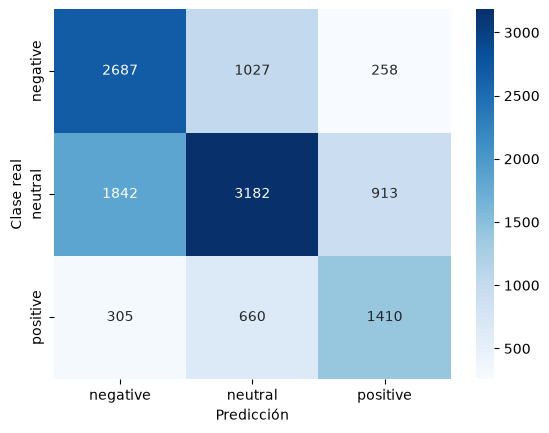

In [ ]:
# Evaluar validación y prueba
valid_pred = model.predict(valid_df["text"])
print("F1 macro validación:", f1_score(valid_df["label"], valid_pred, average="macro"))

test_pred = model.predict(test_df["text"])
print(classification_report(
    test_df["label"], test_pred,
    target_names=labels, digits=3
))

"""
- precision / recall / f1-score: por clase (definidas en el Bloque 1).
- support: cuántos ejemplos reales hay de esa clase en test.
- accuracy: porcentaje total de aciertos.
- macro avg: promedio simple de las tres clases. Trata a todas por igual.
weighted avg: promedio ponderado por support. Se parece más al accuracy porque domina la clase grande.
"""
cm = confusion_matrix(test_df["label"], test_pred)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=labels, yticklabels=labels)
plt.xlabel("Predicción")
plt.ylabel("Clase real")
plt.show()

In [13]:
# Examinar errores
errors = test_df.copy()
errors["prediction"] = test_pred
errors = errors[errors["label"] != errors["prediction"]]
errors["real"] = errors["label"].map(dict(enumerate(labels)))
errors["predicted"] = errors["prediction"].map(dict(enumerate(labels)))
errors[["text", "real", "predicted"]].sample(20, random_state=42)

,text,real,predicted
9140,"With the most powerful binoculars, I cannot se...",neutral,positive
8021,@user The dividing lines that these new fascis...,negative,neutral
10816,@user #CapitalistArmy #MemeWars against libera...,negative,neutral
11987,How Medical Marijuana Could Combat the Opioid ...,neutral,negative
10374,2/2 #Yanukovich to #Ukraine ppl: @user give or...,neutral,negative
241,#Marijuana is medicine. 4 a very authoritative...,neutral,negative
3475,Vernon RCMP Cracking Down on Medical Marijuana...,neutral,negative
8541,Anyone else realised that getting a #Hatchimal...,neutral,negative
1217,Eat out and stay #Healthy. Yes. It is possible...,positive,neutral
4892,"Sodastream:.How to profit from Occupation, Opp...",neutral,negative


In [14]:
# Verificaciones mínimas
assert len(test_pred) == len(test_df)
assert set(np.unique(test_pred)).issubset({0, 1, 2})
assert "tfidf" in model.named_steps
assert "classifier" in model.named_steps
print("Verificaciones superadas")

Verificaciones superadas


- ¿Qué errores parecen relacionados con negación, ironía o falta de contexto?
- ¿Qué clase obtiene menor recall?
- ¿Cambiaría la decisión si los falsos negativos tuvieran mayor costo?
- ¿Qué limitaciones tendría aplicar el modelo a mensajes dominicanos en español?